# MovieLens Recommender: PSO and ALS Demonstration

This notebook demonstrates the data split, PSO factorization, ALS refinement, and ranking metrics. To keep the interactive run manageable, model fitting uses a reproducible subsample of the full MovieLens 1M data. **These demo numbers are not the final benchmark.** The complete five-seed benchmark is in `results/benchmark_summary.md` and `results/benchmark_all.csv`.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_movielens_1m, get_split, make_subsample
from src.metrics import rmse, mae, ranking_metrics
from src.pso import PSOConfig, PSORecommender
from src.als_reference import ALSReference
from src.hybrid import HybridRecommender


## 1. Load MovieLens and create the fixed split

The loader accepts `data/ml-1m/ratings.dat`. We use split seed 42, matching the experiments. The held-out test set is not used to fit these models.


In [2]:
ratings = load_movielens_1m(str(ROOT / "data"))
split = get_split(ratings, seed=42)

pd.DataFrame([
    {"part": "train", "ratings": len(split.train)},
    {"part": "validation", "ratings": len(split.val)},
    {"part": "train_full", "ratings": len(split.train_full)},
    {"part": "test", "ratings": len(split.test)},
])


,part,ratings
0,train,720105
1,validation,80088
2,train_full,800193
3,test,200016


## 2. Prepare a fast demonstration sample

The full dataset has 6,040 users and 3,706 movies. For this notebook demo, we select at most 500 users and 500 popular movies, then re-index and split this sample. The final benchmark files still contain results from the full MovieLens 1M dataset.


In [3]:
demo_ratings = make_subsample(ratings, n_users=500, n_items=500, seed=0)
demo_split = get_split(demo_ratings, seed=42)
print(f"Demo sample: {demo_ratings.n_users:,} users, {demo_ratings.n_items:,} movies, {len(demo_ratings):,} ratings")
print(f"Demo train: {len(demo_split.train):,}; demo test: {len(demo_split.test):,}")


Demo sample: 500 users, 500 movies, 41,154 ratings
Demo train: 29,631; demo test: 8,233


## 3. Fit PSO, ALS, and the PSO → ALS hybrid

`FAST=True` keeps the PSO budget small for teaching and demonstration. It does not change the configurations used in the full benchmark.


In [4]:
FAST = True
if not FAST:
    raise ValueError("This notebook is configured for the quick demo run.")

pso = PSORecommender(PSOConfig(
    d=5,
    n_particles=6,
    max_evals=60,
    lam=0.05,
    init_std=0.03,
    seed=0,
))
pso.fit(demo_split.train)

als = ALSReference(d=5, lam=0.05, n_iter=5, seed=0)
als.fit(demo_split.train)

hybrid = HybridRecommender(
    meta=pso,
    refiner=ALSReference(d=5, lam=0.05, n_iter=5, seed=0),
)
hybrid.refine(demo_split.train)
print("PSO evaluations:", pso.n_evals)
print("Hybrid reuses the fitted PSO factors, then refines them with ALS.")


PSO evaluations: 60
Hybrid reuses the fitted PSO factors, then refines them with ALS.


## 4. Compare rating and ranking metrics

Precision and recall use held-out ratings of at least 4 stars as relevant, exclude movies already seen in training, and average over users with at least one relevant test movie.


In [5]:
rows = []
for name, model in [("PSO", pso), ("ALS", als), ("PSO + ALS", hybrid)]:
    predictions = model.predict(demo_split.test.users, demo_split.test.items)
    ranking = ranking_metrics(model, demo_split.train, demo_split.test)
    rows.append({
        "model": name,
        "RMSE": rmse(demo_split.test.ratings, predictions),
        "MAE": mae(demo_split.test.ratings, predictions),
        "Precision@10": ranking["precision@10"],
        "Recall@10": ranking["recall@10"],
    })
pd.DataFrame(rows).round(4)


,model,RMSE,MAE,Precision@10,Recall@10
0,PSO,1.0238,0.8184,0.0296,0.0222
1,ALS,0.9045,0.7034,0.0621,0.0469
2,PSO + ALS,0.9090,0.7085,0.0586,0.0476


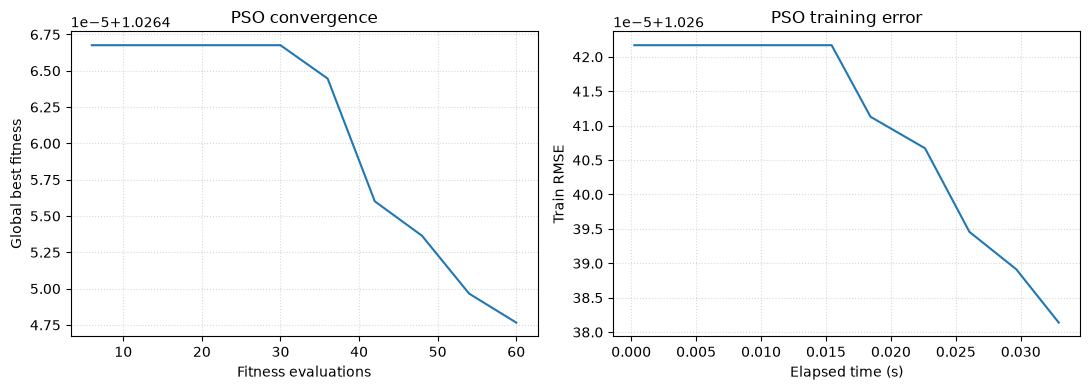

In [6]:
history = pso.history_df()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["n_evals"], history["gbest_fitness"])
axes[0].set(xlabel="Fitness evaluations", ylabel="Global best fitness", title="PSO convergence")
axes[1].plot(history["time_s"], history["rmse_train"])
axes[1].set(xlabel="Elapsed time (s)", ylabel="Train RMSE", title="PSO training error")
for axis in axes:
    axis.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()


## 5. Open the full benchmark results

The final benchmark uses all MovieLens 1M ratings, five seeds (0–4), and the held-out test split. Open these files for the full per-seed table, mean/std summary, and comparison plot:

- `results/benchmark_all.csv`
- `results/benchmark_summary.csv`
- `results/benchmark_summary.md`
- `results/figures/benchmark_comparison.png`


In [7]:
summary_path = ROOT / "results" / "benchmark_summary.csv"
if summary_path.exists():
    benchmark = pd.read_csv(summary_path)
    display(benchmark[["method", "n_seeds", "rmse_test_mean", "rmse_test_std", "prec@10_mean", "rec@10_mean"]].round(4))
else:
    print("Run `python experiments/c_final_report.py` from the project root to build the final benchmark summary.")


,method,n_seeds,rmse_test_mean,rmse_test_std,prec@10_mean,rec@10_mean
0,als,5,0.8582,0.0005,0.0212,0.0102
1,als_reference_10it,5,0.8607,0.0008,0.0215,0.0103
2,als_reference_30it,5,0.8576,0.0004,0.0209,0.0101
3,bpr,5,NaN,NaN,0.2194,0.1362
4,global_mean,5,1.1158,0.0000,0.0106,0.0060
5,item_mean,5,0.9777,0.0000,0.0001,0.0001
6,popularity,5,NaN,NaN,0.1514,0.0914
7,pso,5,1.1159,0.0000,0.0050,0.0023
8,pso+als,5,0.8609,0.0005,0.0211,0.0102
9,sgd,5,0.8760,0.0002,0.0962,0.0554


## 6. Partie B — baselines et hyperparamètres retenus

Les configurations ont été choisies sur validation. Les résultats ci-dessous sont mesurés sur le test pour cinq seeds. BPR est évalué uniquement sur le ranking.


In [8]:
from IPython.display import display, Image, Markdown

b7_path = ROOT / "results" / "B7_hyperparameters.md"
display(Markdown(b7_path.read_text(encoding="utf-8")))

all_results = pd.read_csv(ROOT / "results" / "benchmark_all.csv")
baseline_methods = ["als", "sgd", "bpr", "global_mean", "user_mean", "item_mean", "popularity"]
summary_cols = ["rmse_test", "mae_test", "prec@10", "rec@10", "fit_time_s", "peak_mem_mb"]
all_results[all_results.method.isin(baseline_methods)].groupby("method")[summary_cols].agg(["mean", "std"]).round(4)


# B7 — Hyperparamètres sélectionnés

Les configurations ont été sélectionnées sur le jeu de validation, avant les expériences finales sur le test. Les grilles complètes sont conservées dans `tuning_als.csv`, `tuning_sgd.csv` et `tuning_bpr.csv` (et leurs résumés).

| Méthode | Configurations testées | Configuration retenue | Critère de validation |
|---|---:|---|---|
| ALS | 24 | `d=10`, `lam=0.05`, `n_iter=20` | `rmse_val` = 0.86064 |
| SGD | 27 | `d=20`, `eta=0.01`, `lam=0.02`, `lr_decay=0.05`, `n_epochs=10`, `patience=3` | `rmse_val` = 0.88168 |
| BPR | 27 | `d=20`, `eta=0.05`, `lam=0.001`, `lr_decay=0.02`, `n_epochs=10`, `relevant_threshold=4.0` | `precision@10` = 0.07648 |

Pour ALS et SGD, la sélection minimise la RMSE de validation. Pour BPR, modèle de classement implicite, elle maximise Precision@10 de validation. Le seuil de pertinence BPR est 4 étoiles.


rmse_test         mae_test         prec@10          rec@10  \
                 mean     std     mean     std    mean     std    mean   
method                                                                   
als            0.8582  0.0005   0.6735  0.0004  0.0212  0.0005  0.0102   
bpr               NaN     NaN      NaN     NaN  0.2194  0.0013  0.1362   
global_mean    1.1158  0.0000   0.9329  0.0000  0.0106  0.0000  0.0060   
item_mean      0.9777  0.0000   0.7811  0.0000  0.0001  0.0000  0.0001   
popularity        NaN     NaN      NaN     NaN  0.1514  0.0000  0.0914   
sgd            0.8760  0.0002   0.6901  0.0002  0.0962  0.0016  0.0554   
user_mean      1.0339  0.0000   0.8283  0.0000  0.0106  0.0000  0.0060   

                    fit_time_s         peak_mem_mb           
                std       mean     std        mean      std  
method                                                       
als          0.0002    27.3128  2.8891    110.2172   2.0821  
bpr          0.0015     2.1700  0.0630     32.9812   0.5098  
global_mean  0.0000     0.1092  0.0179      6.1992   0.0055  
item_mean    0.0000     0.1014  0.0003      6.2453   0.0051  
popularity   0.0000     0.1112  0.0226      6.7781   0.3478  
sgd          0.0014     5.1997  0.5238    197.8133  11.7659  
user_mean    0.0000     0.1115  0.0230      7.5680   2.7289

## 7. Partie B — coût computationnel et qualité

Les figures comparent la qualité avec le temps, la mémoire et les cycles d’optimisation, puis montrent les fronts de Pareto.


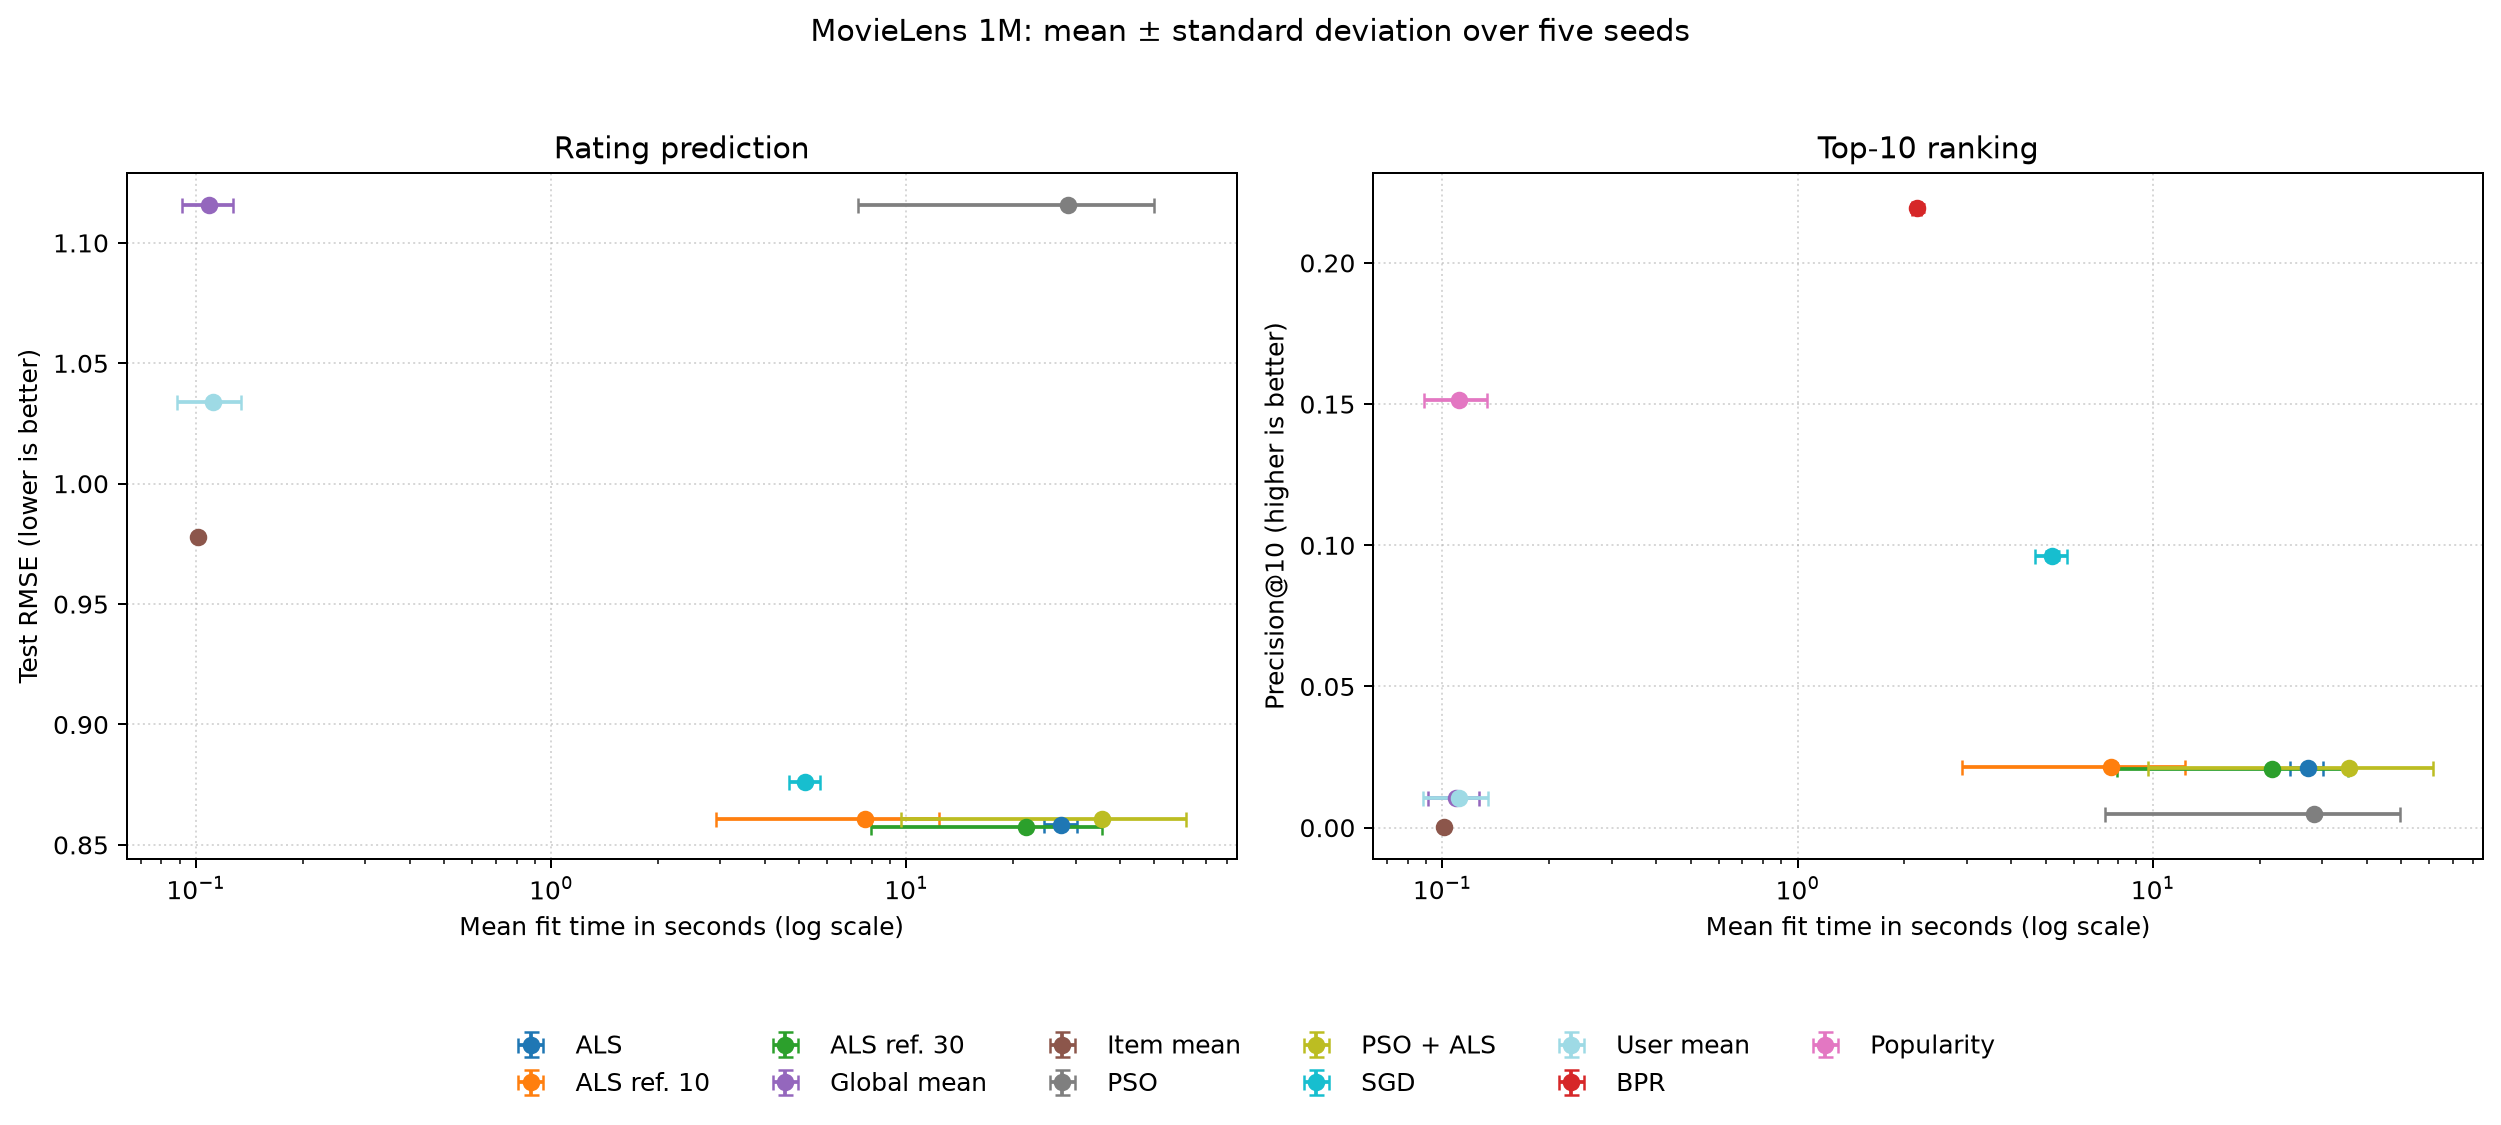

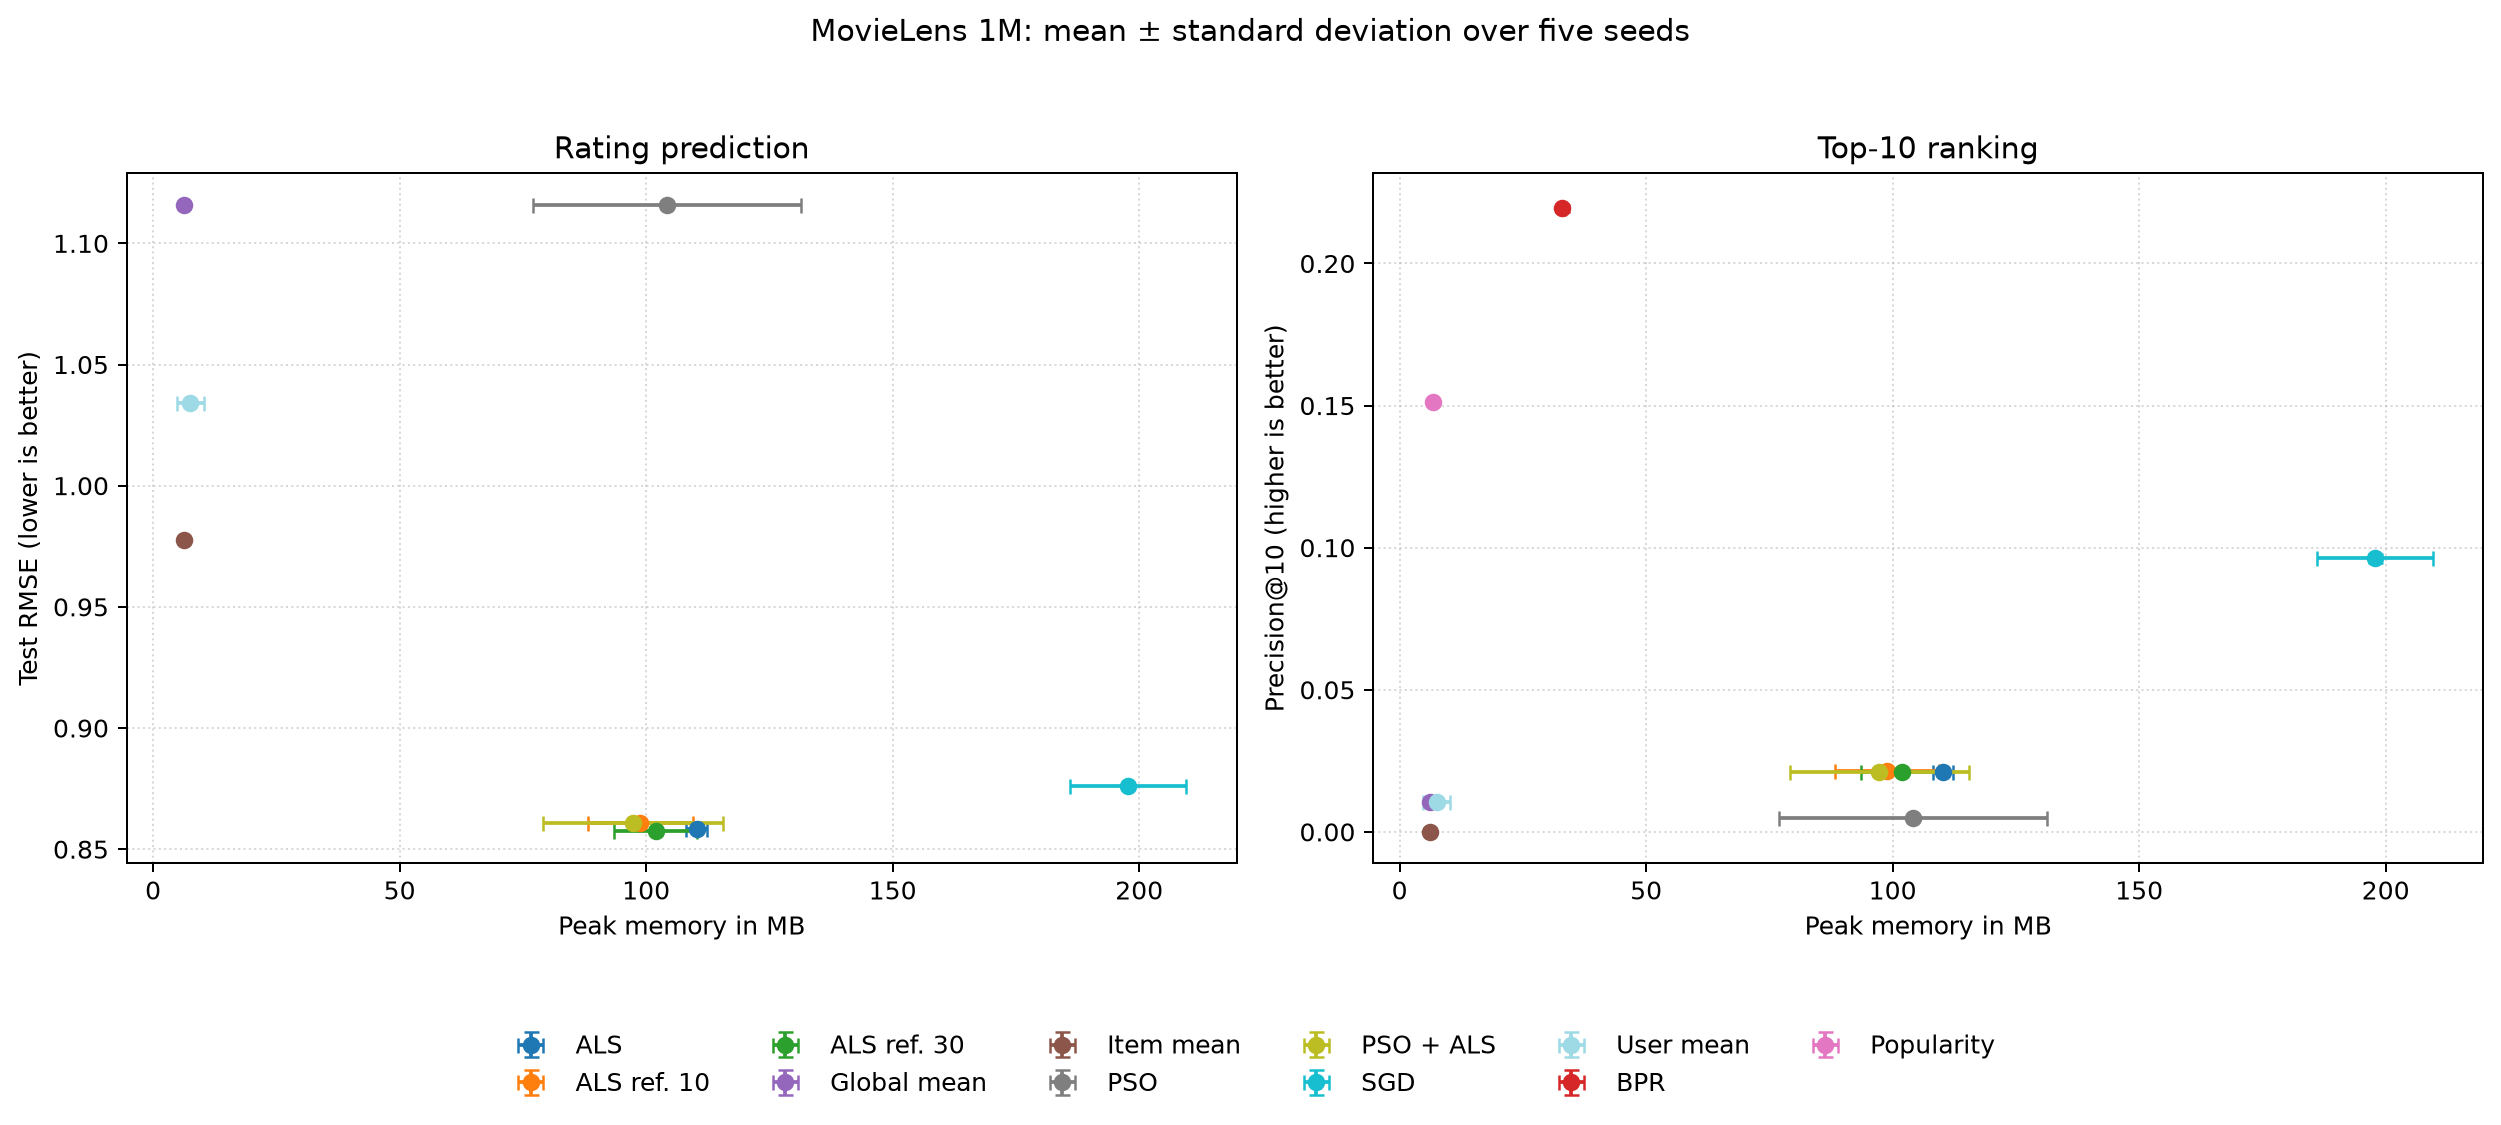

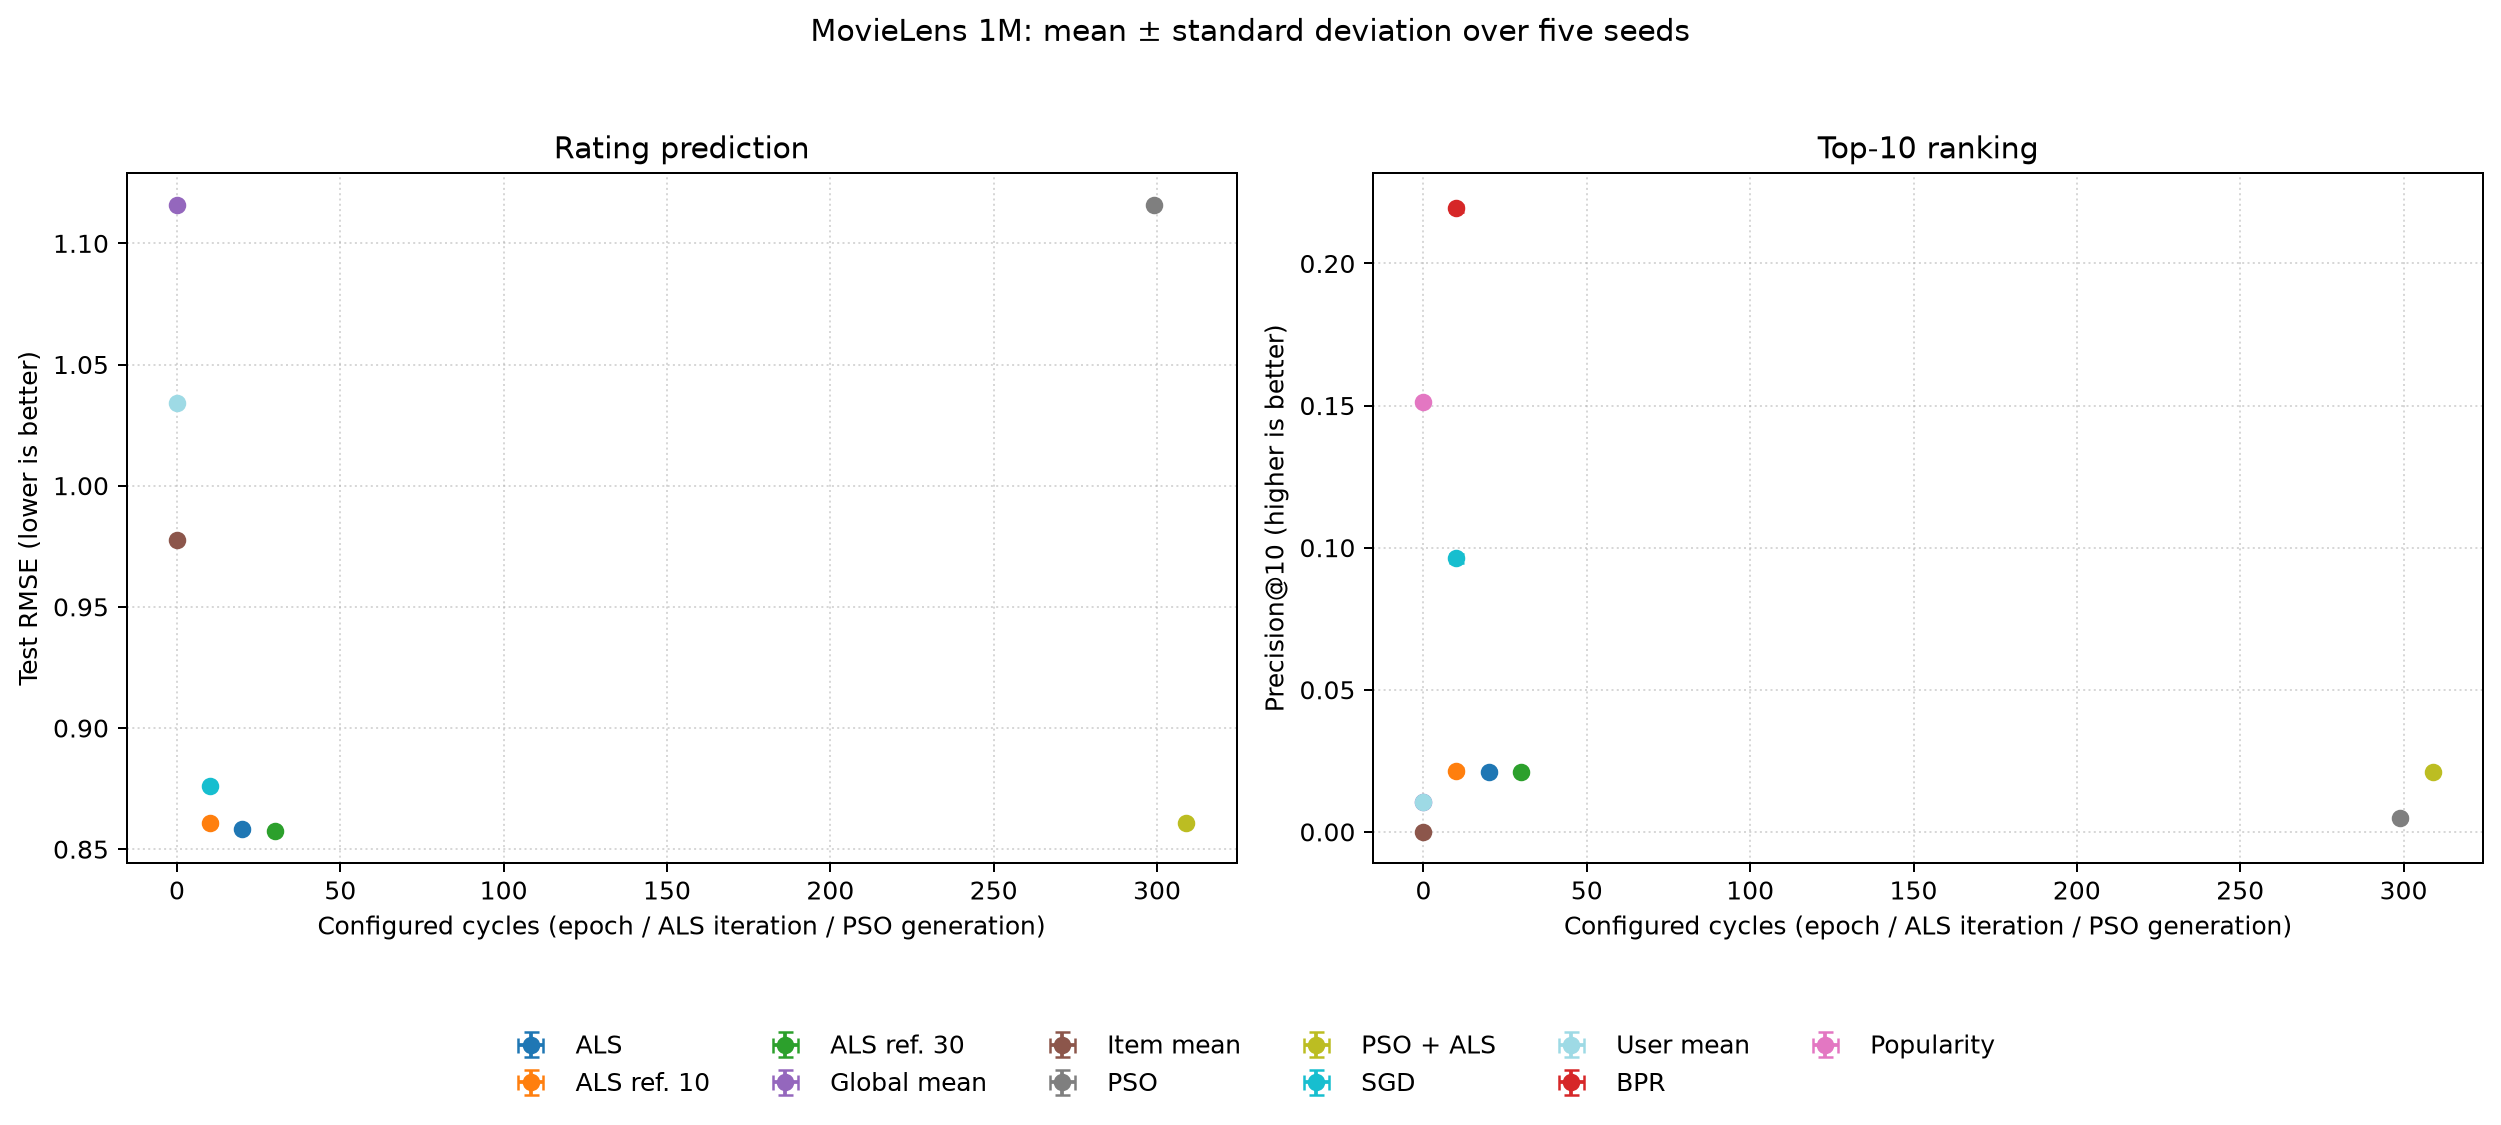

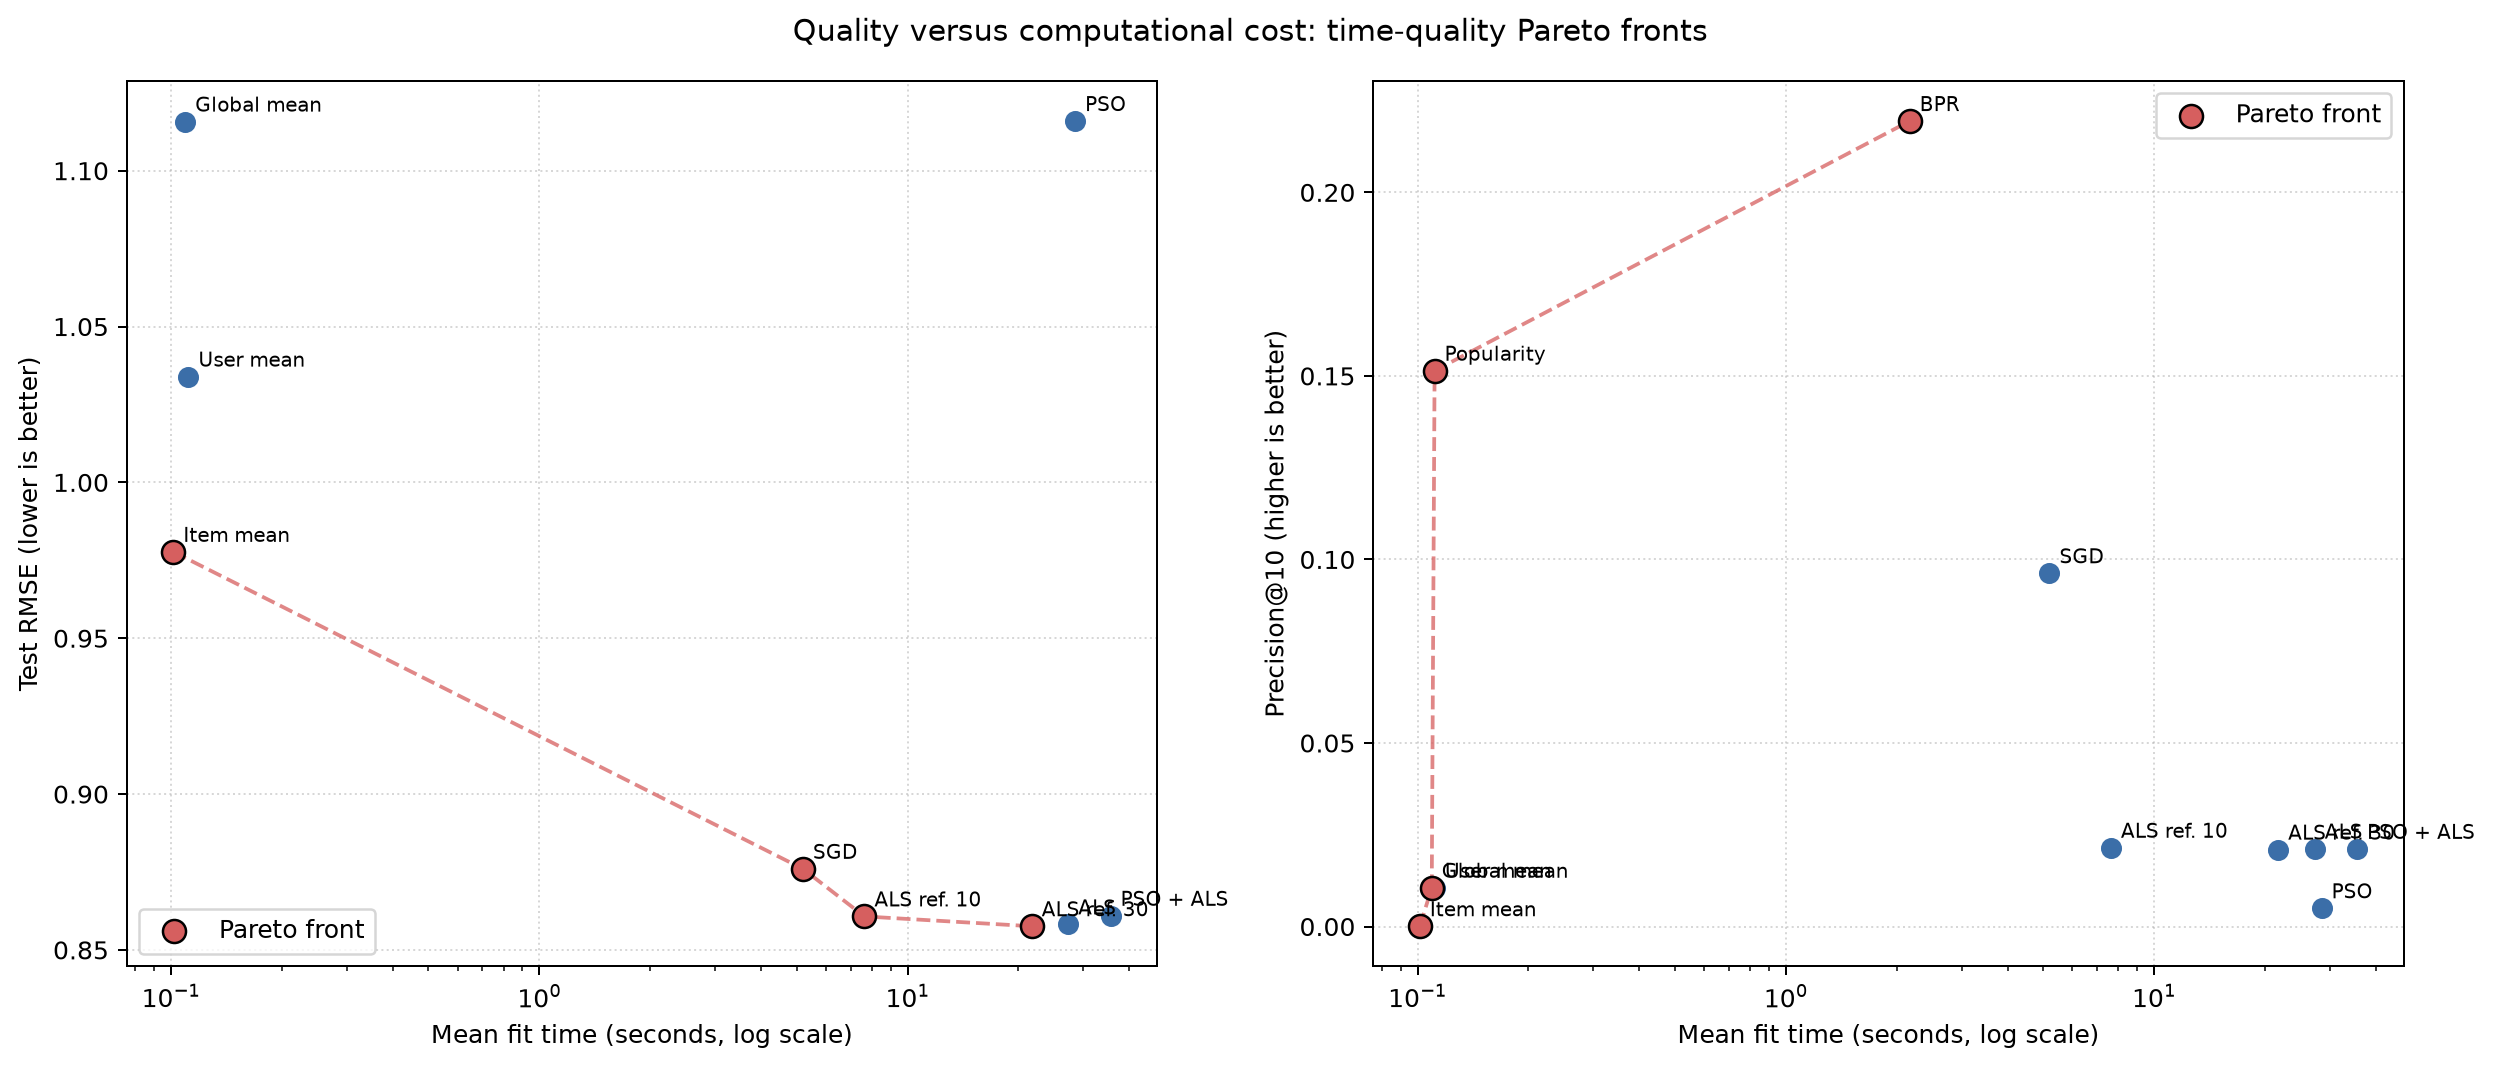

# B9 — Analyse du coût computationnel et de la qualité

## Protocole et lecture des résultats

Les mesures ci-dessous proviennent du benchmark MovieLens 1M : 1 000 209 notes au total, 6 040 utilisateurs et 3 706 films. Le split par utilisateur utilise la seed 42 ; le réglage utilise la validation, les entraînements finaux sont faits sur `train_full`, et le jeu de test contient 200 016 notes. Toutes les méthodes finales sont présentes sur cinq seeds (0–4). Les valeurs sont présentées en moyenne ± écart-type. Les temps et la mémoire reflètent cette exécution sur une machine Windows/Anaconda ; ils dépendent du matériel, du système, des bibliothèques et de la charge en arrière-plan.

Pour le ranking, une note de test ≥ 4 est pertinente, les films déjà vus en entraînement sont exclus et la moyenne porte sur les utilisateurs ayant au moins un film pertinent dans le test. BPR et Popularity sont des méthodes de classement : leur RMSE/MAE n'est pas défini. Les métriques ranking des deux ALS de référence sont calculées à partir de modèles réentraînés sur le même `train_full`.

## Résultats observés

| Méthode | RMSE test | P@10 | Temps moyen (s) | Mémoire de crête moyenne (MB) | Cycles configurés |
|---|---:|---:|---:|---:|---:|
| ALS | 0.8582 ± 0.0005 | 0.0212 ± 0.0005 | 27.31 ± 2.89 | 110.2 ± 2.1 | 20 |
| ALS ref. 10 | 0.8607 ± 0.0008 | 0.0215 ± 0.0008 | 7.64 ± 4.73 | 98.8 ± 10.6 | 10 |
| ALS ref. 30 | 0.8576 ± 0.0004 | 0.0209 ± 0.0005 | 21.73 ± 13.77 | 102.0 ± 8.4 | 30 |
| BPR | — | 0.2194 ± 0.0013 | 2.17 ± 0.06 | 33.0 ± 0.5 | 10 |
| Global mean | 1.1158 ± 0.0000 | 0.0106 ± 0.0000 | 0.11 ± 0.02 | 6.2 ± 0.0 | 0 |
| Item mean | 0.9777 ± 0.0000 | 0.0001 ± 0.0000 | 0.10 ± 0.00 | 6.2 ± 0.0 | 0 |
| Popularity | — | 0.1514 ± 0.0000 | 0.11 ± 0.02 | 6.8 ± 0.3 | 0 |
| PSO | 1.1159 ± 0.0000 | 0.0050 ± 0.0007 | 28.52 ± 21.18 | 104.2 ± 27.2 | 299 |
| PSO + ALS | 0.8609 ± 0.0005 | 0.0211 ± 0.0004 | 35.60 ± 25.92 | 97.3 ± 18.2 | 309 |
| SGD | 0.8760 ± 0.0002 | 0.0962 ± 0.0016 | 5.20 ± 0.52 | 197.8 ± 11.8 | 10 |
| User mean | 1.0339 ± 0.0000 | 0.0106 ± 0.0000 | 0.11 ± 0.02 | 7.6 ± 2.7 | 0 |

The fit-time plots use a logarithmic time axis to show both the very short mean/popularity baselines and the longer latent-factor methods. The memory plots compare measured peak RSS above each process baseline. Cycle counts use the model's own unit: SGD/BPR epochs, ALS sweeps, PSO generations, and the sum of PSO generations plus ALS sweeps for the hybrid. Those units describe workload within each algorithm and should not be interpreted as identical operations. The zero-cycle simple baselines are closed-form aggregation methods.

### Theoretical work per iteration

Let Ω be the training ratings, with |Ω| = 800,193, users n_u = 6,040, items n_i = 3,706, latent dimension d, and PSO population N. ALS-WR solves one d-by-d system per user and item: approximately O(|Ω| d² + (n_u+n_i)d³) per full ALS sweep; storage is O(|Ω|+(n_u+n_i)d). This matches its relatively high measured wall time for d=10 and 20 sweeps (27.31 s mean for the tuned Part B ALS).

SGD visits each observed rating and updates two d-dimensional vectors: O(|Ω|d) per epoch, with O(|Ω|+(n_u+n_i)d) storage. Its measured 10-epoch fit averages 5.20 s and 197.8 MB. It has a good rating RMSE (0.8760) and stronger P@10 (0.0962) than the non-personalized rating baselines, while using more measured memory than the other fitted models in this run.

BPR samples positive/negative user-item triplets. For S sampled triplets per epoch, its work is O(Sd) per epoch and its factor/storage requirement is O((n_u+n_i)d), plus sampling/index structures. It is ranking-only by design. At the tuned configuration its mean P@10 is 0.2194, above Popularity at 0.1514, with 2.17 s mean fit time and 33.0 MB peak memory. Thus it is the strongest top-10 ranking method in these measurements, at substantially lower time than ALS or PSO. Its quality should be judged only by ranking metrics.

PSO evaluates a population of candidate factor matrices. A full fitness evaluation costs O(|Ω|d); E evaluations therefore cost O(E|Ω|d). The population, velocities and best-so-far states require O(N(n_u+n_i)d) memory. At E=6,000 and N=20, the pure PSO averages 28.52 s and 104.2 MB, yet its RMSE is 1.1159 and P@10 is 0.0050. It has a high computational cost without competitive predictive or ranking quality on this large search space.

The PSO+ALS hybrid combines the PSO evaluation cost with ten ALS sweeps, as confirmed by the saved per-seed histories. It averages 35.60 s, 97.3 MB and RMSE 0.8609, with P@10 0.0212. ALS alone averages RMSE 0.8582 and P@10 0.0212 at 27.31 s. On these metrics, the PSO stage adds cost without a measurable quality advantage over tuned ALS. The hybrid is far better than PSO alone, showing that ALS refinement accounts for most of its rating and ranking quality.

The global/user/item means and popularity are closed-form baselines with one pass over ratings or counts, O(|Ω|+n_u+n_i) work and small state. They fit in about 0.10–0.11 s and under 8 MB peak memory here. They are useful cost floors. Global mean reaches RMSE 1.1158, while popularity reaches P@10 0.1514; a baseline can therefore be weak on one task and competitive on another.

## Pareto and statistical interpretation

On the RMSE/time plane, the Pareto front contains: ALS ref. 10, ALS ref. 30, Item mean, SGD. On the P@10/time plane, it contains: BPR, Global mean, Item mean, Popularity. A method is on the front if no other measured method is both faster and at least as good on that metric. This is a descriptive comparison of five-seed averages, not a guarantee for every seed. The separate time and memory figures show that the trade-off changes with the selected objective: BPR is particularly effective for ranking, while ALS/SGD are stronger choices for calibrated rating prediction.

Paired t-tests are exploratory because they use only five paired seeds and assume the seed-wise differences are approximately normal:
- Test t apparié als vs pso+als sur `rmse_test` : n=5, t=-19.047, p=4.476e-05.
- Test t apparié als vs als_reference_30it sur `rmse_test` : n=5, t=5.985, p=0.003918.
- Test t apparié bpr vs popularity sur `prec@10` : n=5, t=118.547, p=3.037e-08.
- Test t apparié als vs sgd sur `rmse_test` : n=5, t=-61.256, p=4.254e-07.

The test results do not replace effect sizes or confidence intervals, and a non-significant result at n=5 is not evidence of equivalence. A practical choice follows the product objective: use BPR when top-k ranking is primary; use ALS or SGD for rating prediction; use simple baselines as cheap reference points. The current measurements do not justify pure PSO for the full MovieLens 1M factorization, and do not show a quality gain from adding PSO before ALS. A metaheuristic's extra cost could be justified when it yields a robust improvement on the chosen metric, solves constraints unavailable to the baseline optimizer, or works better on a smaller search domain; none of those advantages is established by this benchmark.

## Generated artifacts

- `results/figures/B9_quality_vs_time.png`
- `results/figures/B9_quality_vs_memory.png`
- `results/figures/B9_quality_vs_cycles.png`
- `results/figures/B9_pareto_fronts.png`
- `results/B9_cost_quality_summary.csv`
- `results/B9_paired_tests.csv`

The cycle counts for PSO+ALS and the recorded configuration metadata were reconciled against the saved convergence histories. The pre-correction input CSV is retained as `results/metaheuristics_before_b9_correction.csv`.


In [9]:
for filename in [
    "B9_quality_vs_time.png",
    "B9_quality_vs_memory.png",
    "B9_quality_vs_cycles.png",
    "B9_pareto_fronts.png",
]:
    display(Image(filename=str(ROOT / "results" / "figures" / filename)))

display(Markdown((ROOT / "results" / "B9_cost_quality_analysis.md").read_text(encoding="utf-8")))
